## Task 1: Dataset Exploration and Understanding

In [3]:
from pathlib import Path

pathData = Path(r"C:\Users\bally\Downloads\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch") # path of file

import pandas as pd

labels = pd.read_csv(pathData / "train_labels.csv");

#assessing the shape and columns of the table
print("Table shape");
print(labels.shape);
print("Columns");
print(labels.columns);

# viewing the top 10 and bottom 10 rows of the table
print("Top 10 rows");
display(labels.head(10));
print("Bottom 10 rows");
display(labels.tail(10));

#data types and null values
print("Table data types and null values");
labels.info();

#summary stats
print("Summary statistics");
display(labels.describe(include = "all"));

Table shape
(63660, 2)
Columns
Index(['image_id', 'class'], dtype='str')
Top 10 rows


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogFace
3,4,DogNose
4,5,DogNose
5,6,DogEye
6,7,DogMouth
7,8,CatNose
8,9,CatFace
9,10,CatNose


Bottom 10 rows


,image_id,class
63650,63651,DogEye
63651,63652,CatFace
63652,63653,CatNose
63653,63654,CatMouth
63654,63655,CatMouth
63655,63656,CatEye
63656,63657,DogMouth
63657,63658,DogEye
63658,63659,DogMouth
63659,63660,CatMouth


Table data types and null values
<class 'pandas.DataFrame'>
RangeIndex: 63660 entries, 0 to 63659
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   image_id  63660 non-null  int64
 1   class     63660 non-null  str  
dtypes: int64(1), str(1)
memory usage: 994.8 KB
Summary statistics


,image_id,class
count,63660.000000,63660
unique,NaN,8
top,NaN,CatEye
freq,NaN,13884
mean,31830.500000,NaN
std,18377.203405,NaN
min,1.000000,NaN
25%,15915.750000,NaN
50%,31830.500000,NaN
75%,47745.250000,NaN


In [4]:
#Checking if the data is balanced
ClassNum = labels['class'].value_counts().sort_index();

display(ClassNum)

class
CatEye      13884
CatFace      6942
CatMouth     6942
CatNose      6942
DogEye      11580
DogFace      5790
DogMouth     5790
DogNose      5790
Name: count, dtype: int64

The dataset is unbalanced, the eye classes have around more than 2x the count than the other classes. It is also observable that there is more counts for the cat features in comparison to the dogs. At this stage I am wondering if the eyes are being counted 2x more due to there being 2 eyes for each image in comparison to the other features.

The next section of this is going to explore if the data label/number matches the actual image

In [5]:
# Checking if the data labels and numbers match of each image
trainPath = pathData / "train"/ "train" # path of training images

for item in sorted(trainPath.iterdir())[:10]: # iterating through the first 10 files in the training folder
    print(item.name)

00001.jpg
00002.jpg
00003.jpg
00004.jpg
00005.jpg
00006.jpg
00007.jpg
00008.jpg
00009.jpg
00010.jpg


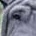

In [6]:
#displaying images of each class,
#this section checks DOG-EYE
#going up and looking at the id numbers printed in the table, id 1 is a dog-eye and should display that

from PIL import Image

picture = Image.open(trainPath / "00001.jpg") # opening the image file
display(picture) # displaying the image
#upon displaying the image is very small and pixilated when zooming in/cannot confirm it is a dog eye

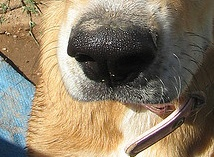

In [7]:
#Checking for DOG-MOUTH
picture = Image.open(trainPath / "00002.jpg") #opening the image file
display(picture) # displaying the image
#confirmed a dog mouth is shown in the image

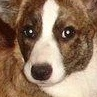

In [8]:
#Checking for DOG-FACE
picture = Image.open(trainPath / "00003.jpg") #opening the image file
display(picture) # displaying the image
#confirmed a dog face is shown in the image

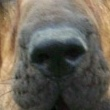

In [9]:
#checking DOG-NOSE
picture = Image.open(trainPath / "00004.jpg")
display(picture)

#confirmed a dog nose is shown

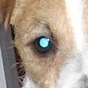

In [10]:
#Rechecking DOG-EYE with another image for confirmatin

picture = Image.open(trainPath / "63651.jpg")
display(picture)
#confirmed dog eye is seen however doing other dog eye images im noticing they are very small/cropped and hard to see

In [11]:
#Checking CAT-EYE
picture = Image.open(trainPath / "63656.jpg")
display(picture)
#confirmed a cat eye is shown

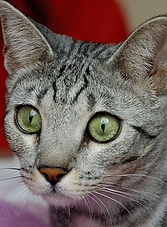

In [12]:
#Checking CAT-FACE
picture = Image.open(trainPath / "63652.jpg")
display(picture)
#confirmed a cat face is shown


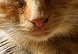

In [13]:
#Checking CAT-MOUTH
picture = Image.open(trainPath / "63654.jpg")
display(picture)
#confirmed a cat mouth is shown

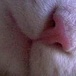

In [14]:
#Checking for CAT-NOSE
picture = Image.open(trainPath / "63653.jpg")
display(picture)
#Cat nose is shown

For cat and dog mouth/noses both the nose and mouth is seen. Image sizes also vary with smaller images being harder to see and are heavily pixilated. To address this the next section will determine if the images are readable by checking if pillow can open them and record size.

In [15]:
#Checking training image sizes

sizes = []
unreadableImages = []

for file in trainPath.glob("*.jpg"):
    try:
        with Image.open(file) as img:
            img.load()  #Load the image to ensure it's readable
            sizes.append(img.size)
    except OSError:
        unreadableImages.append(file.name)

print(f"Number of unreadable images: {len(unreadableImages)}")
print(f"Number of readable images: {len(sizes)}")

count_sizeNum = pd.Series(sizes).value_counts()
display(count_sizeNum.head(10))  #Display the top 10 most common sizes

print("Unique image sizes:")
print(len(count_sizeNum))
print("Total images checked:")
print(len(sizes) + len(unreadableImages))


Number of unreadable images: 0
Number of readable images: 63660


(40, 40)    1062
(48, 48)    1051
(42, 42)    1050
(38, 38)    1002
(44, 44)    1002
(46, 46)     985
(34, 34)     978
(36, 36)     963
(54, 54)     952
(52, 52)     928
Name: count, dtype: int64

Unique image sizes:
7861
Total images checked:
63660


As observable, there are around 7861 different image sizings, however 40 x 40, 48 x 48, 42 x 42 etc are amongst the most prominent ones. Since for batch training images must be the same size, images will be resized during the preprocessing stage.

In [16]:
#Checking missing values

print("Missing Values:")
print(labels.isnull().sum().sum())

#Checking for duplicate entries in the labels DataFrame
print("Duplicate Entries:")
print(labels["image_id"].duplicated().sum())

#no duplicate entries or missing values were found

Missing Values:
0
Duplicate Entries:
0


In [17]:
#Seeing if there are dupliciated images in the training folder using hashlib

import hashlib

seen_hashes = {}
duplicate_images = []

for file in trainPath.glob("*.jpg"):
    try:
        with open(file, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()
            if file_hash in seen_hashes:
                duplicate_images.append((seen_hashes[file_hash], file.name))
            else:
                seen_hashes[file_hash] = file.name
    except OSError:
        print(f"Could not read file: {file.name}")  

print(f"Number of duplicate images: {len(duplicate_images)}")
print("Duplicate image names:")
for dup in duplicate_images:
    print(dup)

Number of duplicate images: 15
Duplicate image names:
('00356.jpg', '06903.jpg')
('07219.jpg', '12150.jpg')
('16730.jpg', '21960.jpg')
('25436.jpg', '40256.jpg')
('03365.jpg', '42280.jpg')
('04003.jpg', '46057.jpg')
('30201.jpg', '50179.jpg')
('36988.jpg', '52755.jpg')
('45625.jpg', '54078.jpg')
('49150.jpg', '55761.jpg')
('35039.jpg', '55965.jpg')
('03926.jpg', '56008.jpg')
('54348.jpg', '57804.jpg')
('33473.jpg', '59020.jpg')
('13090.jpg', '63140.jpg')


Displayed duplicate pair 1: 00356.jpg and 06903.jpg


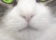

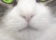

Displayed duplicate pair 2: 07219.jpg and 12150.jpg


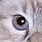

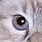

Displayed duplicate pair 3: 16730.jpg and 21960.jpg


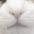

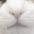

Displayed duplicate pair 4: 25436.jpg and 40256.jpg


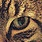

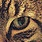

Displayed duplicate pair 5: 03365.jpg and 42280.jpg


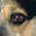

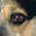

Displayed duplicate pair 6: 04003.jpg and 46057.jpg


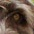

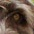

Displayed duplicate pair 7: 30201.jpg and 50179.jpg


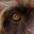

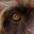

Displayed duplicate pair 8: 36988.jpg and 52755.jpg


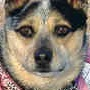

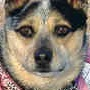

Displayed duplicate pair 9: 45625.jpg and 54078.jpg


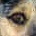

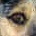

Displayed duplicate pair 10: 49150.jpg and 55761.jpg


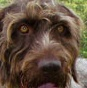

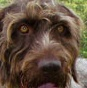

Displayed duplicate pair 11: 35039.jpg and 55965.jpg


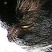

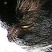

Displayed duplicate pair 12: 03926.jpg and 56008.jpg


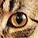

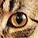

Displayed duplicate pair 13: 54348.jpg and 57804.jpg


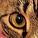

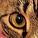

Displayed duplicate pair 14: 33473.jpg and 59020.jpg


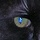

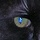

Displayed duplicate pair 15: 13090.jpg and 63140.jpg


In [18]:
#Confirming visally these are indeed duplicates

#displaying duplicate images side by side for visual confirmation
for i, (img1, img2) in enumerate(duplicate_images):
    picture1 = Image.open(trainPath / img1)
    picture2 = Image.open(trainPath / img2)
    
    display(picture1, picture2)
    print(f"Displayed duplicate pair {i+1}: {img1} and {img2}")
    #it is confirmed that thee following pairs are duplicated of eachother, this is important to remove as it can cause a bias in the model and result
    #in the model performance being overstimated. 
    

In [19]:
#Checking if these images fall under the same class or not, if they do not then this is a problem and needs to be fixed

class_mismatches = []
for img1, img2 in duplicate_images:

    id1 = int(Path(img1).stem); #Extract ID from image path
    id2 = int(Path(img2).stem);

    class1 = labels.loc[labels['image_id'] == id1, 'class'].values[0]
    class2 = labels.loc[labels['image_id'] == id2, 'class'].values[0]

    if class1 != class2:
        class_mismatches.append((img1, img2, class1, class2))

print(f"Number of class mismatches among duplicates: {len(class_mismatches)}")
#No mismatches between image classes were found for duplicates

Number of class mismatches among duplicates: 0


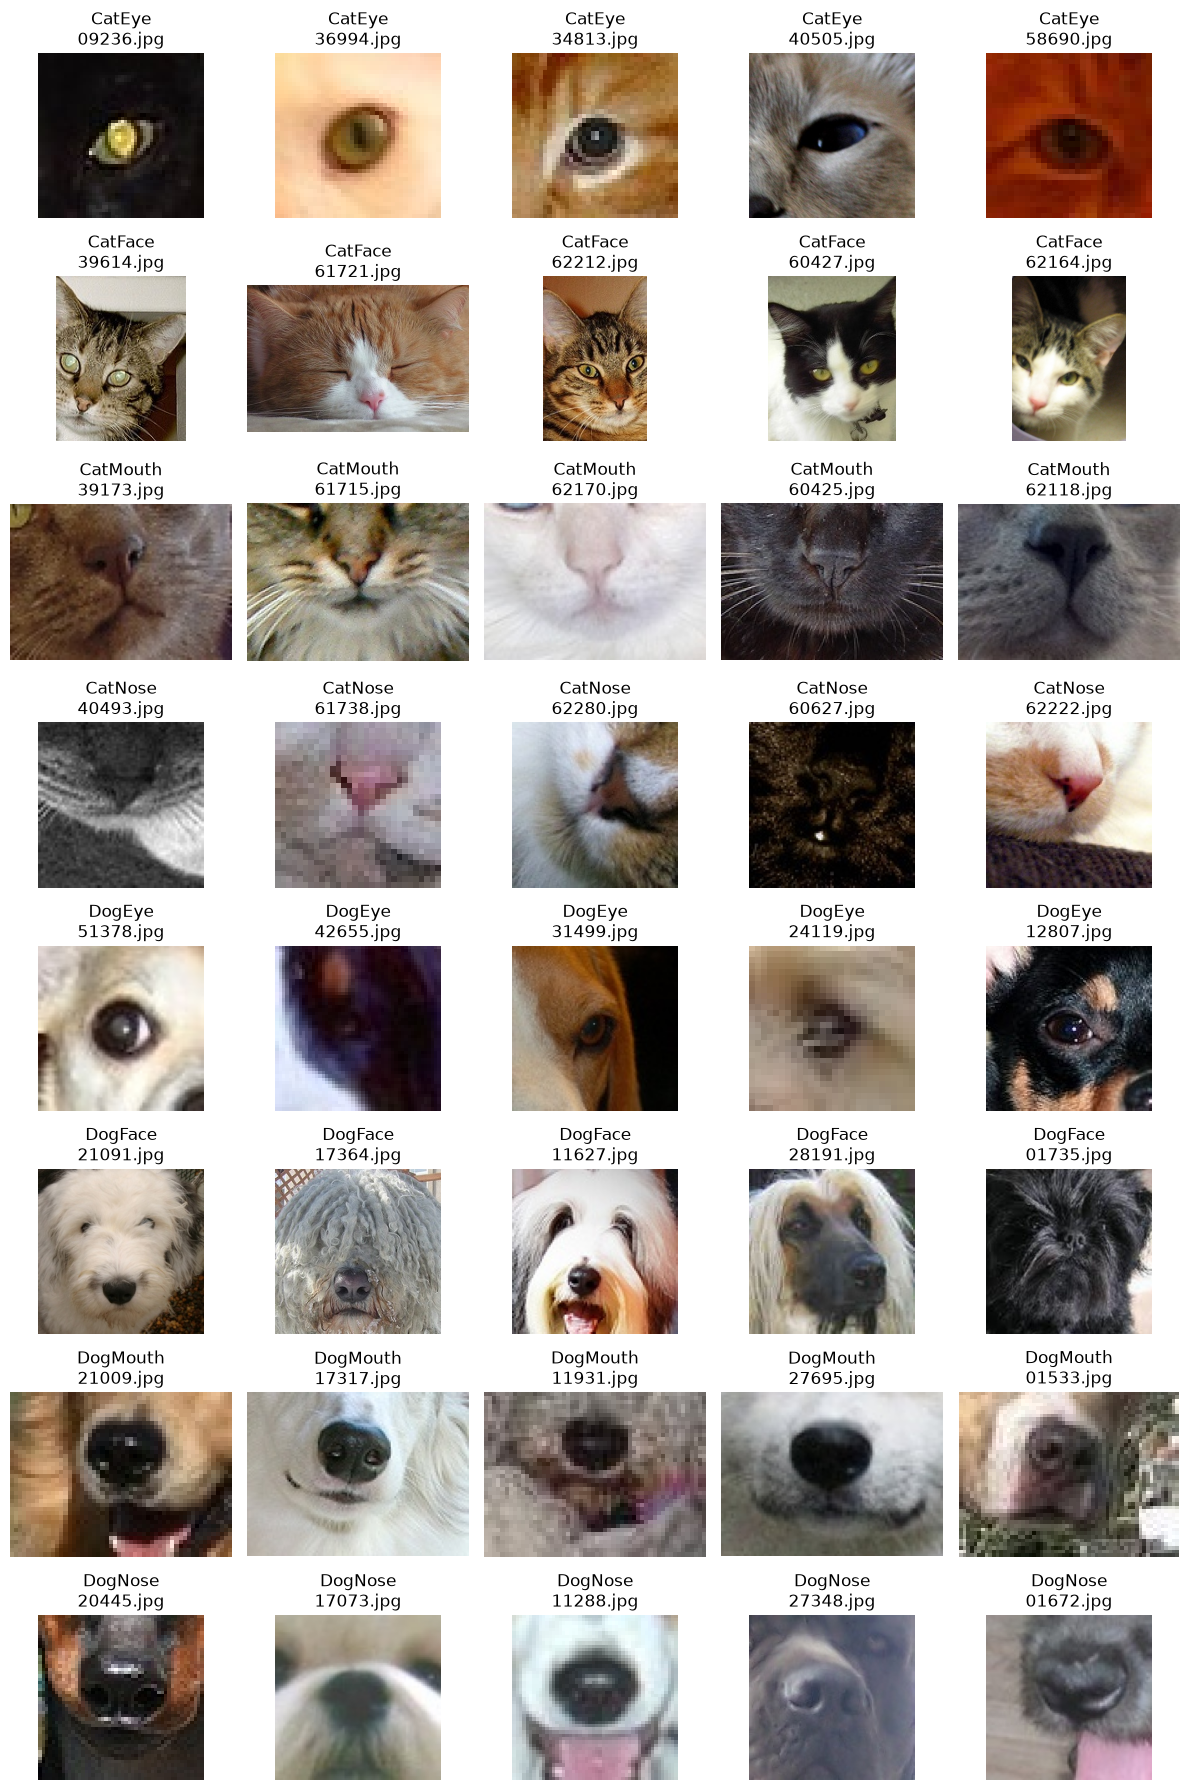

In [20]:
#Visual Inspectin of image blurriness
#using matplotlib to plot the images in a grid for visual inspection of blurriness

import matplotlib.pyplot as plt

classes = sorted(labels['class'].unique())

fig, axes = plt.subplots(len(classes), 5, figsize=(12, 18))

for row, cls in enumerate(classes):
    class_images = labels[labels['class'] == cls]['image_id'].sample(5, random_state=42)  # sample 5 images for each class
    
    for col, img_id in enumerate(class_images):
        img_path = trainPath / f"{img_id:05d}.jpg"

        with Image.open(img_path) as img:
            axes[row, col].imshow(img)
            axes[row, col].axis('off')
            axes[row, col].set_title(f"{cls}\n{img_id:05d}.jpg")



plt.tight_layout()
plt.show()

It is observable that there is blurriness throughout the datasets training images, most of the images are deciplerable however there shows to be a few images that are not easily recognisable such as image 24119 and 42655. This could mean that the model may encounter difficulty between identifying the different classes.

# 1.1 - Doing the same for the Test file

In [21]:

testFile = pathData / "test" / "test" #path of test images

test_num = len(list(testFile.glob("*.jpg")))
print(f"Number of test images: {test_num}")

Number of test images: 29443


In [22]:
#Checking test image sizes and readability

test_sizes = []
unreadable_test_images = []

for file in testFile.glob("*.jpg"):
    try:
        with Image.open(file) as img:
            img.load()  # Load the image to ensure it's readable
            test_sizes.append(img.size)
    except OSError:
        unreadable_test_images.append(file.name)

print (f"Number of unreadable test images: {len(unreadable_test_images)}")
print(f"Number of readable test images: {len(test_sizes)}")

print("Unique test image sizes:")
test_size_counts = pd.Series(test_sizes).value_counts()
print(len(test_size_counts))

print("Top 10 Common Test Image Sizes:")
display(test_size_counts.head(10))  #Display the top 10 most common test image sizes

Number of unreadable test images: 0
Number of readable test images: 29443
Unique test image sizes:
7786
Top 10 Common Test Image Sizes:


(40, 40)    503
(50, 50)    402
(80, 80)    370
(30, 30)    349
(60, 60)    343
(70, 70)    260
(64, 64)    185
(50, 40)    177
(90, 90)    162
(62, 62)    162
Name: count, dtype: int64

No unreadable images but similarily lots of images with different sizes are in the test file images.

In [23]:
#Checking for duplicates in the test file

seen_hashes2 = {}
duplicate_images2 = []

for file in testFile.glob("*.jpg"):
    try:
        with open(file, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()
            if file_hash in seen_hashes2:
                duplicate_images2.append((seen_hashes2[file_hash], file.name))
            else:
                seen_hashes2[file_hash] = file.name
    except OSError:
        print(f"Could not read file: {file.name}")  

print(f"Number of duplicate images: {len(duplicate_images2)}")
print("Duplicate image names:")
for dup in duplicate_images2:
    print(dup)


Number of duplicate images: 62
Duplicate image names:
('01193.jpg', '03316.jpg')
('00358.jpg', '04502.jpg')
('03597.jpg', '05541.jpg')
('06483.jpg', '07112.jpg')
('02878.jpg', '10562.jpg')
('03249.jpg', '10840.jpg')
('03984.jpg', '11481.jpg')
('00942.jpg', '11992.jpg')
('09022.jpg', '12179.jpg')
('00562.jpg', '12598.jpg')
('11341.jpg', '12960.jpg')
('04630.jpg', '14167.jpg')
('12944.jpg', '14527.jpg')
('02588.jpg', '14699.jpg')
('01879.jpg', '15998.jpg')
('05154.jpg', '16013.jpg')
('00480.jpg', '17140.jpg')
('00881.jpg', '17204.jpg')
('06862.jpg', '17246.jpg')
('01640.jpg', '17330.jpg')
('00744.jpg', '17849.jpg')
('08419.jpg', '17984.jpg')
('14295.jpg', '18391.jpg')
('09948.jpg', '18445.jpg')
('03488.jpg', '18937.jpg')
('09855.jpg', '18987.jpg')
('12235.jpg', '19501.jpg')
('17157.jpg', '19528.jpg')
('10527.jpg', '19869.jpg')
('11650.jpg', '20114.jpg')
('01185.jpg', '20179.jpg')
('03602.jpg', '20291.jpg')
('02646.jpg', '20571.jpg')
('11328.jpg', '21441.jpg')
('06798.jpg', '21507.jpg')
(

A larger set of duplicated images is seen in the test file, however these will be kept as each image will still need its own predicition.

## Task 2: Data Preprocessing and Pipeline Preparation

In [24]:
#Removing duplicate values

duplicate_image_ids = []

for original, duplicate in duplicate_images:
    duplicate_image_ids.append(int(Path(duplicate).stem))  #Extract ID from image path and convert to int

clean_labels = labels[~labels['image_id'].isin(duplicate_image_ids)].copy() #Remove duplicates from labels DataFrame

print("Original count:", len(labels))
print("Clean count:", len(clean_labels))

Original count: 63660
Clean count: 63645


For the training and testing split, an stratified 80/20 split will be chosen. This is because due to the large dataset, thousands of images will make it to the testing split. Due to stratification, the same percentage of class counts will remain constant within the testing and training splits. The 80/20 split was chosen over k-fold cross-examination to save computational effort and time, so more time can be given to comparing the results against more models.

In [25]:
#Setting up the training and validation dataset

from sklearn.model_selection import train_test_split

train_labels, val_labels = train_test_split(clean_labels, test_size=0.2, 
                                            stratify=clean_labels['class'], 
                                            random_state=42)

print("Training set size:", len(train_labels))
print("Validation set size:", len(val_labels))
#training size of approx 50,000 and validation size of approx 12,500 
# - suffiently enough image for both training and testing the model


Training set size: 50916
Validation set size: 12729


In [26]:
#Assigning a number to each class for model training

classes = sorted(clean_labels['class'].unique())
class_to_index = {name: index for index, name in enumerate(classes, start = 0)} #assigns from 0 onwards

train_labels = train_labels.copy() #copies the training and test laebels 
val_labels = val_labels.copy()

train_labels['labels'] = train_labels['class'].map(class_to_index) #assigns a number to each class in the training and validation labels
val_labels['labels'] = val_labels['class'].map(class_to_index)

print(class_to_index) 
display(train_labels.head(10))

{'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}


,image_id,class,labels
26976,26977,CatNose,3
43789,43790,DogMouth,6
60044,60045,CatEye,0
47429,47430,DogEye,4
50147,50148,DogMouth,6
32483,32484,DogEye,4
59588,59589,CatEye,0
50359,50360,DogEye,4
36671,36672,DogNose,7
52486,52487,CatEye,0


Transformed image shape: torch.Size([3, 64, 64])


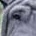

torch.Size([3, 64, 64])


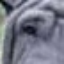

In [27]:
#To train the model a high-level library - pytorch will be utilised
#resizing the images for batch testing
#checking if image becomes successfully resized

import torch
from torchvision import transforms

size_image = (64, 64) #Resize images to 64x64 pixels

transform = transforms.Compose([
    transforms.Resize(size_image),
    transforms.ToTensor()
])

with Image.open(trainPath / "00001.jpg") as img:
    transformed_img = transform(img.convert("RGB")) 
    print("Transformed image shape:", transformed_img.shape)  
    #output shows that the image has gotten resized

    picture = Image.open(trainPath / "00001.jpg") #opening the image file
    display(picture) # displaying the image
    print(transformed_img.shape)  #Transformed image size
    display(transforms.ToPILImage()(transformed_img))  #Display the resized image

    #it is observable that the image has been successfully resized

In [28]:

#Setting up the dataset class and defining methods for loading the images and labels

from torch.utils.data import Dataset

class FacialFeaturesDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_id = self.dataframe.iloc[idx]['image_id']
        label = self.dataframe.iloc[idx]['labels'] 
        img_path = self.image_dir / f"{img_id:05d}.jpg"
        
        with Image.open(img_path) as img:
            img = img.convert("RGB")
            if self.transform:
                img = self.transform(img)
        
        return img, label

In [29]:
train_dataset = FacialFeaturesDataset(train_labels, trainPath, transform) #testing if the dataset class works correctly by loading training lavels, its path and its transform

image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Model label:", label)
display(train_labels.iloc[0]) #checking if the label matches image id, class and assigned number for its class

Image shape: torch.Size([3, 64, 64])
Model label: 3


image_id      26977
class       CatNose
labels            3
Name: 26976, dtype: object

In [30]:
#the dataset images now will be split into batches to prepare for model training - dataloader will be used for this

from torch.utils.data import DataLoader

#validation dataset created using dataset class "facialfeaturesdataset"
val_dataset = FacialFeaturesDataset(val_labels, trainPath, transform)
#training dataset was defined above

In [31]:
#Data augmentation will be done on the training dataset to reduce overfitting and improve model performance
#this will be done by moving the features slightly in the images through vertical/horizontal shifts/flips or rotation

transforming_train = transforms.Compose(
    [transforms.Resize(size_image),
     transforms.RandomAffine(degrees=8, translate = (0.03, 0.03)),
     transforms.RandomHorizontalFlip(p = 0.2),
     transforms.ToTensor() ])
#the transforms above will apply to the training data, not validation


#resizing the train data:
train_dataset = FacialFeaturesDataset(train_labels, trainPath, transforming_train)

#resizing the validation data
val_dataset = FacialFeaturesDataset(val_labels, trainPath, transform)

#grouping the validation and training dataset in batches of 32 images for model training and testing
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True) #training shuffle is on to ensure the model doesnt learn the order of the images
#for training that reduces overfitting
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

#checking a batch
images, labels_batch = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch labels shape:", labels_batch.shape)

#checking the validation batch
val_images, val_batch_labels = next(iter(val_loader))
print("Validation batch shape:", val_images.shape)

#batches have been succesfully prepared with 32 images, 3 channels, and 64x64 pixels

Batch image shape: torch.Size([32, 3, 64, 64])
Batch labels shape: torch.Size([32])
Validation batch shape: torch.Size([32, 3, 64, 64])


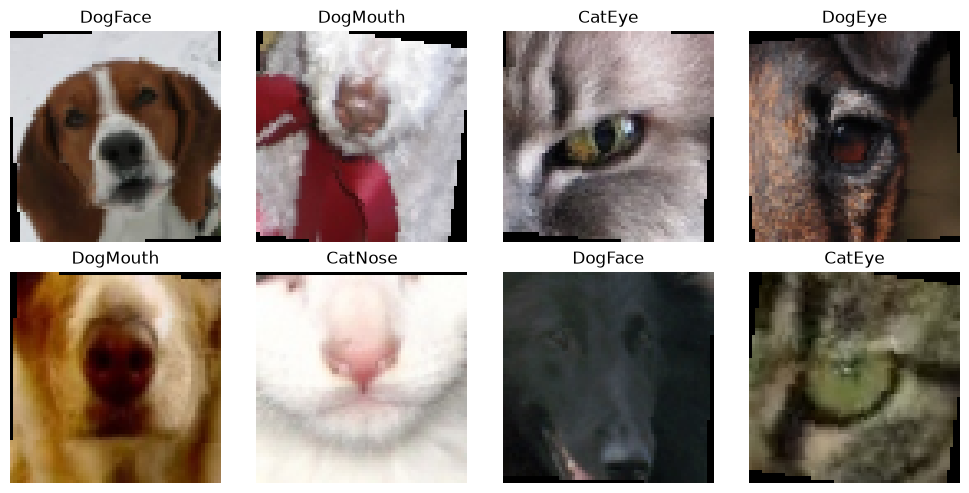

In [32]:
#Checking if the training images havent been modified too greatly where they are indistinguishable visually

fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].permute(1, 2, 0))
    ax.set_title(classes[labels_batch[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()
#images show to be distinguishable

In [33]:
#Preparing Test Data
#loading sample submission as a reference point for ids
sample_submission = pd.read_csv(pathData / "sample_submission.csv")

#using dataset to load the test data

class TestDataset(Dataset):
    def __init__(self, image_ids, image_dir, transform):
        self.image_ids = list(image_ids)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = int(self.image_ids[idx])
        image_path = self.image_dir / f"{image_id:05d}.jpg"

        with Image.open(image_path) as img:
            image = self.transform(img.convert("RGB"))

        return image, image_id


#creating test dataset
test_data = TestDataset(sample_submission['image_id'], testFile, transform )

#test loader for splitting into batches
test_load = DataLoader(test_data, batch_size=32, shuffle=False, num_workers = 0)


## Task 3: Model Selection and Pipeline Development

In [34]:
import torch.nn as nn

In [ ]:
#Creating a custom CNN model


torch.manual_seed(42)

model = nn.Sequential(nn.Conv2d(3, 16, kernel_size = 3, padding = 1), #16 filters for 3 color channels
                      nn.ReLU(),#negative values will become 0
                      nn.MaxPool2d(kernel_size=2), #maximum downsampled is 2x2 window
                      nn.Conv2d(16, 32, kernel_size = 3, padding = 1),#repeating with 16 feature maps and 32 filters
                      nn.ReLU(),
                      nn.MaxPool2d(kernel_size=2),#window is downsampled again

                      #adding classifiers - turn image into one set of values, e.g (32*16*16 = 8192), then learn 128 weighted combinations from the values
                      nn.Flatten(), nn.Linear(32 * 16 * 16, 128), nn.ReLU(),nn.Linear(128, 8)#outputs one score for each one of the classes
                      )

#calculating prediction error for each of the classes

loss_func = nn.CrossEntropyLoss()
#the optimiser chosen is Adam
optim = torch.optim.Adam(model.parameters(), lr = 0.001) #learning rate set initially to 0.001 and may be tweaked during training


In [ ]:
#training model once to display the pipeline

model.train()

#the pipeline follows prediction, calculating the loss for that batch, calculate the adjustments needed and then updating the weights according to that
images, labels_batch = next(iter(train_loader))
optim.zero_grad()#clearing any previous gradients
output = model(images) #output is the predicted score from the model for class
loss = loss_func(output, labels_batch) #calculating the error of prediction
loss.backward() #calculating the weights that can change error
optim.step() #updating the weights

print("prediction error (loss):", loss.item())

prediction error (loss): 2.0718936920166016


In [86]:
#creating a function to train one epoch

def epoch(model, train_loader, loss_func, optim):

    model.train()
    sum_loss = 0
    true =0
    imageCount = 0

    for images, labels_batch in train_loader:
        optim.zero_grad()
        output = model(images) 
        loss = loss_func(output, labels_batch) 
        loss.backward() 
        optim.step()

        batch_size = images.size(0)
        sum_loss += loss.item() * batch_size
        predict = output.argmax(dim = 1)
        true += (predict == labels_batch).sum().item()
        imageCount += batch_size

    e_loss = sum_loss/imageCount
    e_accur = true/imageCount

    return e_loss, e_accur



In [38]:
#creating a validation function
#this function will check if the model perdicts the image classes accuractely on those that werent in the train split
def validation (model, val_loader, loss_func):
    model.eval()

    sum_loss = 0
    true = 0
    imageCount = 0

    with torch.no_grad():
        for images, labels_batch in val_loader:
            output = model(images)
            loss = loss_func(output, labels_batch)

            batch_size = images.size(0)
            sum_loss += loss.item() * batch_size

            predict = output.argmax(dim=1)
            true += (predict == labels_batch).sum().item()
            imageCount += batch_size

    v_loss = sum_loss / imageCount
    v_accur = true / imageCount

    return v_loss, v_accur
    

In [90]:
#running one epoch to test and check if the training and validation of model works

epochCount = 1
previous = []
best_loss_scoreVal = float("inf")

for epoch_count in range(epochCount):
    train_loss, train_accuracy = epoch(model, train_loader, loss_func, optim) #running function for model training

    val_loss, val_accuracy = validation(model, val_loader, loss_func) #running function for model validation

    #storing results of each epoch for evaluating the model later into this project
    previous.append({"epoch": epoch_count + 1, "train loss": train_loss, "train accuracy": train_accuracy, 
                     "validation loss": val_loss, "validation accuracy": val_accuracy})

    #displaying the results from training
    print(f"Epoch", epoch_count + 1)
    print(f"Train loss:", train_loss)
    print(f"Train accuracy:", train_accuracy)
    print(f"Validation loss:", val_loss)
    print(f"Validation accuracy:", val_accuracy)

    #applying code to save the best model
    if val_loss < best_loss_scoreVal:
        best_loss_scoreVal = val_loss
        torch.save(model.state_dict(), "BestModel.pth") #ensures model weights have also been replaced for the best one


Epoch 1
Train loss: 0.2642992683435724
Train accuracy: 0.913288553696284
Validation loss: 0.19896507605012415
Validation accuracy: 0.9364443396967554


For the first epoch, validation accuracy is slightly higher than training - this makes sense because the training images have been augmented to reduce overfitting of the model. There is no apparent sign of overfitting yet of the model and more epochs may have to be run to guage a better understanding of the models.

## Task 4 and 5: Training Strategy and Overfitting/Underfitting Management and Kaggle Submissions

In [93]:
#lowering weight adjustment to see if that results in a better model accuracy

for group in optim.param_groups:
    group["lr"] = 0.0003

In [96]:
#training the model with more epochs

epochCount = 3
epochsDone = len(previous) #stores the amount of epochs already done

for epoch_count in range(epochsDone, epochsDone + epochCount): #ranges it from 1 to 5 so 4 more epochs are done
    train_loss, train_accuracy = epoch(model, train_loader, loss_func, optim) #running function for model training

    val_loss, val_accuracy = validation(model, val_loader, loss_func) #running function for model validation

    #storing results of each epoch for evaluating the model later into this project
    previous.append({"epoch": epoch_count + 1, "train loss": train_loss, "train accuracy": train_accuracy, 
                     "validation loss": val_loss, "validation accuracy": val_accuracy})

    #displaying the results from training
    print(f"Epoch", epoch_count + 1)
    print(f"Train loss:", train_loss)
    print(f"Train accuracy:", train_accuracy)
    print(f"Validation loss:", val_loss)
    print(f"Validation accuracy:", val_accuracy)

    #applying code to save the best model
    if val_loss < best_loss_scoreVal:
        best_loss_scoreVal = val_loss
        torch.save(model.state_dict(), "BestModel.pth") #ensures model weights have also been replaced for the best one

Epoch 16
Train loss: 0.049696814848206074
Train accuracy: 0.9831487155314635
Validation loss: 0.07858251909847482
Validation accuracy: 0.9740749469714824
Epoch 17
Train loss: 0.048544505026635
Train accuracy: 0.9842878466493833
Validation loss: 0.07187851147840828
Validation accuracy: 0.9759604053735564
Epoch 18
Train loss: 0.04619870282315516
Train accuracy: 0.9843271270327598
Validation loss: 0.06993535232153447
Validation accuracy: 0.9769031345745934


From epochs 6-10, training had helped increse the validation datas accuracy to 97.12%, 5 more epochs will be trained by lowering the weight adjustment in the model to see if that results in better model performance.

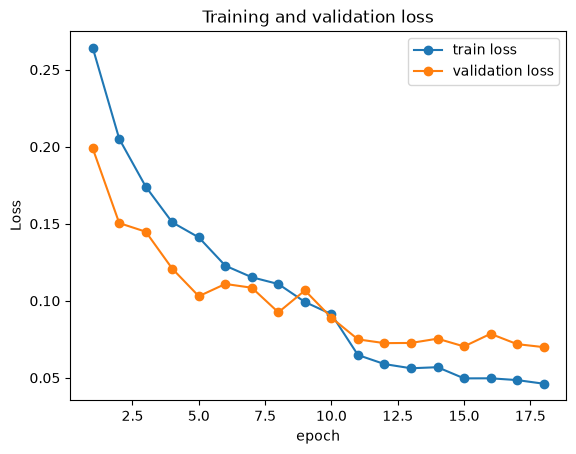

In [97]:
results = pd.DataFrame(previous)

results.plot(
    x="epoch",
    y=["train loss", "validation loss"],
    marker="o",
    ylabel="Loss",
    title="Training and validation loss"
)

plt.show()

Training loss keeps fallings however validation loss gradient becomes less steep and this would mean generalisation of the model may start to occur. To view what images the model is incorrectly classifying, a confusion matrix will be analysed.

In [101]:
#Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display as show_table

actual_labels = []
predicted_labels = []

model.eval()

with torch.no_grad():
    for images, labels_batch in val_loader:
        output = model(images)
        predictions = output.argmax(dim=1)

        actual_labels.extend(labels_batch.cpu().tolist())
        predicted_labels.extend(predictions.cpu().tolist())

class_names = [
    "CatEye", "CatFace", "CatMouth", "CatNose",
    "DogEye", "DogFace", "DogMouth", "DogNose"
]

matrix = confusion_matrix(
    actual_labels, predicted_labels, labels=range(8)
)

matrix_table = pd.DataFrame(
    matrix,
    index=class_names,
    columns=class_names
)

matrix_table.index.name = "Actual"
matrix_table.columns.name = "Predicted"

show_table(matrix_table)

Predicted,CatEye,CatFace,CatMouth,CatNose,DogEye,DogFace,DogMouth,DogNose
Actual,,,,,,,,
CatEye,2737,2,2,7,21,1,0,5
CatFace,1,1379,3,1,2,2,0,1
CatMouth,2,5,1319,51,3,1,6,1
CatNose,12,3,31,1327,6,0,2,7
DogEye,29,8,3,5,2249,6,2,13
DogFace,3,12,1,0,3,1134,2,3
DogMouth,1,3,0,2,3,1,1141,7
DogNose,3,1,1,0,4,0,0,1149


Before strating the process to better the model, best model will be tested on kaggle to evaluate its performance.

In [ ]:
model.load_state_dict(torch.load("BestModel.pth", map_location="cpu", weights_only=True)) #loading best model
model.eval()

#running model for kaggle submission

class_names = [
    "CatEye", "CatFace", "CatMouth", "CatNose",
    "DogEye", "DogFace", "DogMouth", "DogNose"
]

image_ids = []
predicted_classes = []

model.eval()

with torch.no_grad():
    for images, ids in test_load:
        predictions = model(images).argmax(dim=1)

        image_ids.extend(ids.cpu().tolist())
        predicted_classes.extend(
            class_names[p] for p in predictions.cpu().tolist()
        )

submission = pd.DataFrame({
    "image_id": image_ids,
    "class": predicted_classes
})

submission = sample_submission[["image_id"]].merge(
    submission,
    on="image_id",
    how="left",
    validate="one_to_one"
)

assert len(submission) == len(sample_submission)
assert submission["class"].notna().all(), "Some predictions are missing."

submission.to_csv("submission.csv", index=False)


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogNose
3,4,DogFace
4,5,CatMouth


Saved predictions: 29443


Best custom CNN model had scored 0.922 on the kaggle dataset, to see if better accuracy can be achieved, a pre trained model will be used. The pretrained model for usage will be the MobileNetV3-Large

In [1]:
#downloading the pretrained mobilenetV3-Large model

from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights

MNV3_model = mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.DEFAULT)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to C:\Users\bally/.cache\torch\hub\checkpoints\mobilenet_v3_large-5c1a4163.pth


100.0%


In [35]:
#For this step, the pretrained weights will be freezed for quicker assessment of the model, unfreezing some weights will happen later on in
#the training process

for parameter in MNV3_model.parameters():
    parameter.requires_grad = False

MNV3_model.classifier[3] = nn.Linear(MNV3_model.classifier[3].in_features, 8)

In [36]:
#Setting up transformation of the images as MNV3 resizes images differently to the custon CNN model
#below the images are resized to 224x224 pixels, which is the size used to train the model with the pretrained weights
#Convret into tensors and normalise the image colors regarding the settings expected from the model
MNV3_imageTransform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), 
                                          transforms.Normalize( mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])

#because pixel size 224x224 use more memory than 64x64, a smaller batch of 16 images will be used for now

#applying the transformation to the images
MNV3_train_data = FacialFeaturesDataset(train_labels, trainPath, MNV3_imageTransform)
MNV3_val_data = FacialFeaturesDataset(val_labels, trainPath, MNV3_imageTransform)

MNV3_train_loader = DataLoader(MNV3_train_data, batch_size=16, shuffle=True)
MNV3_val_loader = DataLoader(MNV3_val_data, batch_size=16, shuffle=False)

In [37]:
#defining the loss function and validator - same as custom CNN model

MNV3_lossFunc = nn.CrossEntropyLoss()

MNV3_optim = torch.optim.Adam(filter(lambda p: p.requires_grad, MNV3_model.parameters()), lr=0.001) #set initially at 0.001 

In [39]:
#function to train one epoch for the MNV3 model

def MNV3_epoch(model, train_loader, loss_func, optim):
    model.train()
    model.features.eval()

    sum_loss = 0 #counts th loss
    correct = 0 #how many are correct
    image_count = 0 #total images done

    for images, labels_batch in train_loader:
        optim.zero_grad()

        output = model(images)
        loss = loss_func(output, labels_batch)

        loss.backward()
        optim.step()

        batch_size = images.size(0)
        sum_loss += loss.item() * batch_size

        predictions = output.argmax(dim=1)
        correct += (predictions == labels_batch).sum().item()
        image_count += batch_size

    return sum_loss / image_count, correct / image_count

In [41]:
#training one epoch for the MNV3 Model

import time

start = time.perf_counter()

MNV3_train_loss, MNV3_train_accuracy = MNV3_epoch(MNV3_model, MNV3_train_loader, MNV3_lossFunc, MNV3_optim) #stores training results

MNV3_val_loss, MNV3_val_accuracy = validation(MNV3_model, MNV3_val_loader, MNV3_lossFunc) #stores validation results

MNV3_previous = [{ #stores the results of each model
    "epoch": 1,
    "train loss": MNV3_train_loss,
    "train accuracy": MNV3_train_accuracy,
    "validation loss": MNV3_val_loss,
    "validation accuracy": MNV3_val_accuracy
}]

MNV3_best_loss = MNV3_val_loss
torch.save(MNV3_model.state_dict(), "MNV3_BestModel.pth")

print(f"Training loss: {MNV3_train_loss:.4f}")
print(f"Training accuracy: {MNV3_train_accuracy:.2%}")
print(f"Validation loss: {MNV3_val_loss:.4f}")
print(f"Validation accuracy: {MNV3_val_accuracy:.2%}")
print(f"Runtime: {(time.perf_counter() - start) / 60:.1f} minutes")

Training loss: 0.4138
Training accuracy: 85.75%
Validation loss: 0.2844
Validation accuracy: 89.85%
Runtime: 47.2 minutes


In [ ]:

MNV3_model.load_state_dict(
    torch.load(
        "MNV3_BestModel.pth",
        map_location="cpu",
        weights_only=True
    )
)

#last three layers of the model are unforzen and free to learn
for parameter in MNV3_model.features[-3:].parameters():
    parameter.requires_grad = True

#smaller adjustments for pretrained layers for fine tuning
MNV3_optim = torch.optim.Adam([
    {
        "params": MNV3_model.features[-3:].parameters(),
        "lr": 0.0001
    },
    {
        "params": filter(
            lambda p: p.requires_grad,
            MNV3_model.classifier.parameters()
        ),
        "lr": 0.0003
    }
])

In [47]:
for extra_epoch in range(9):
    start = time.perf_counter()

    train_loss, train_accuracy = MNV3_epoch(
        MNV3_model, MNV3_train_loader, MNV3_lossFunc, MNV3_optim
    )

    val_loss, val_accuracy = validation(
        MNV3_model, MNV3_val_loader, MNV3_lossFunc
    )

    MNV3_previous.append({
        "epoch": len(MNV3_previous) + 1,
        "train loss": train_loss,
        "train accuracy": train_accuracy,
        "validation loss": val_loss,
        "validation accuracy": val_accuracy
    })

    if val_loss < MNV3_best_loss:
        MNV3_best_loss = val_loss
        torch.save(MNV3_model.state_dict(), "MNV3_BestModel.pth")

    print("Completed epoch:", MNV3_previous[-1]["epoch"])
    print(f"Training accuracy: {train_accuracy:.2%}")
    print(f"Validation accuracy: {val_accuracy:.2%}")
    print(f"Validation loss: {val_loss:.4f}")
    print(
        f"Runtime: {(time.perf_counter() - start) / 60:.1f} minutes",
        flush=True
    )

    pd.DataFrame(MNV3_previous).to_csv(
        "MNV3_history.csv", index=False
    )

Completed epoch: 4
Training accuracy: 99.07%
Validation accuracy: 98.26%
Validation loss: 0.0527
Runtime: 47.2 minutes
Completed epoch: 5
Training accuracy: 99.39%
Validation accuracy: 98.19%
Validation loss: 0.0541
Runtime: 46.1 minutes
Completed epoch: 6
Training accuracy: 99.61%
Validation accuracy: 98.39%
Validation loss: 0.0560
Runtime: 45.7 minutes
Completed epoch: 7
Training accuracy: 99.70%
Validation accuracy: 98.19%
Validation loss: 0.0615
Runtime: 45.1 minutes
Completed epoch: 8
Training accuracy: 99.68%
Validation accuracy: 98.43%
Validation loss: 0.0522
Runtime: 45.2 minutes
Completed epoch: 9
Training accuracy: 99.75%
Validation accuracy: 97.64%
Validation loss: 0.0936
Runtime: 44.8 minutes
Completed epoch: 10
Training accuracy: 99.80%
Validation accuracy: 98.44%
Validation loss: 0.0539
Runtime: 45.2 minutes
Completed epoch: 11
Training accuracy: 99.88%
Validation accuracy: 98.66%
Validation loss: 0.0564
Runtime: 45.4 minutes
Completed epoch: 12
Training accuracy: 99.76%


The MNV3 Model shows greater accuracy without the data augmented imsgaes, the next step will be to add the transformed images for training the mode

In [50]:
#applying data augmentation to training images 

MNV3_trainImagesTranform = transforms.Compose([transforms.Resize((224, 224)),transforms.RandomAffine(degrees=8, translate=(0.03, 0.03)),
    transforms.RandomHorizontalFlip(p=0.2), transforms.ToTensor(),transforms.Normalize(mean=[0.485, 0.456, 0.406],std=[0.229, 0.224, 0.225])])

MNV3_train_data = FacialFeaturesDataset(train_labels, trainPath, MNV3_trainImagesTranform)
MNV3_train_loader = DataLoader(MNV3_train_data, batch_size= 16, shuffle = True)

In [51]:
#retraining from best saved model
MNV3_model.load_state_dict(torch.load("MNV3_BestModel.pth", map_location="cpu", weights_only=True))

#resetting the optimiser to start with this model for training
MNV3_optim = torch.optim.Adam([
    {"params": MNV3_model.features[-3:].parameters(),"lr": 0.0001},
    {"params": filter(lambda p: p.requires_grad, MNV3_model.classifier.parameters()),"lr": 0.0003}])

torch.save(MNV3_model.state_dict(), "MNV3_AugmentedBest.pth") #saves best weights for augmented images

In [53]:
MNV3_augBestAccuracy = 0.9843
MNV3_aug_previous = []

In [56]:
#starting training againn with the augmented images

for extra_epoch in range(4):
    start = time.perf_counter()


    train_loss, train_accuracy = MNV3_epoch(
        MNV3_model, MNV3_train_loader, MNV3_lossFunc, MNV3_optim
    )

    val_loss, val_accuracy = validation(
        MNV3_model, MNV3_val_loader, MNV3_lossFunc
    )

    MNV3_aug_previous.append({
        "epoch": len(MNV3_aug_previous) + 1,
        "train loss": train_loss,
        "train accuracy": train_accuracy,
        "validation loss": val_loss,
        "validation accuracy": val_accuracy
    })

    if MNV3_augBestAccuracy < val_accuracy:
        MNV3_augBestAccuracy = val_accuracy
        torch.save(MNV3_model.state_dict(), "MNV3_AugmentedBest.pth")

    print("Completed epoch:", MNV3_aug_previous[-1]["epoch"])
    print(f"Training accuracy: {train_accuracy:.2%}")
    print(f"Validation accuracy: {val_accuracy:.2%}")
    print(f"Validation loss: {val_loss:.4f}")
    print(
        f"Runtime: {(time.perf_counter() - start) / 60:.1f} minutes",
        flush=True
    )

    pd.DataFrame(MNV3_aug_previous).to_csv("MNV3_aug_history.csv", index=False)

Completed epoch: 3
Training accuracy: 99.53%
Validation accuracy: 98.66%
Validation loss: 0.0514
Runtime: 62.0 minutes
Completed epoch: 4
Training accuracy: 99.58%
Validation accuracy: 98.70%
Validation loss: 0.0460
Runtime: 53.4 minutes
Completed epoch: 5
Training accuracy: 99.61%
Validation accuracy: 98.75%
Validation loss: 0.0484
Runtime: 56.6 minutes
Completed epoch: 6
Training accuracy: 99.71%
Validation accuracy: 98.92%
Validation loss: 0.0447
Runtime: 73.3 minutes


First epoch for the augmented data had lower validation accuracy in comparison to the baseline, one more epoch will be conducted to observe if accuracy increases or decreases and whether continuing this experiment is worth it.

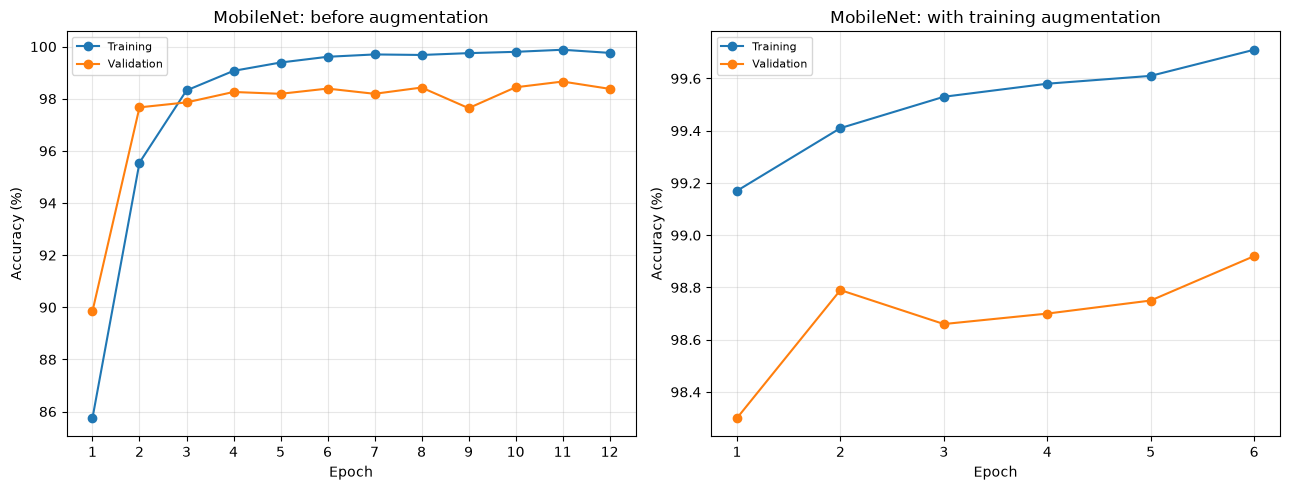

In [64]:
#plotting accuracy results before and after adding data augmented images into training for the MobileNet model
#results beofre data augmentation for MobileNet Model
mobile_train = [85.75, 95.55, 98.32, 99.07, 99.39, 99.61, 99.70, 99.68, 99.75, 99.80, 99.88, 99.76]
mobile_val = [89.85, 97.67, 97.86, 98.26, 98.19, 98.39, 98.19, 98.43, 97.64, 98.44, 98.66, 98.38]
#stores augmentation results
aug_train = [99.17, 99.41, 99.53, 99.58, 99.61, 99.71]
aug_val = [98.30, 98.79, 98.66, 98.70, 98.75, 98.92]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(range(1, 13), mobile_train, "o-", label="Training")
axes[0].plot(range(1, 13), mobile_val, "o-", label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Accuracy (%)", title="MobileNet: before augmentation")
axes[0].set_xticks(range(1, 13))
axes[1].plot(range(1, 7), aug_train, "o-", label="Training")
axes[1].plot(range(1, 7), aug_val, "o-", label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy (%)", title="MobileNet: with training augmentation")
axes[1].set_xticks(range(1, 7))

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("MobileNet_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()